<div style="background:#1F3864;color:white;padding:14px 18px;border-radius:6px"><b>INTERNATIONAL UNIVERSITY – VNU-HCMC · SCHOOL OF COMPUTER SCIENCE AND ENGINEERING</b><br>IT171IU · Statistical Learning</div>

# Lab 6: Moving Beyond Linearity

*Polynomial regression, step functions, regression and natural splines, smoothing splines, local regression and generalized additive models (GAMs)*

**Chapter:** ISLP Chapter 7 · **Duration:** 150 minutes (3 periods) · **Runs on:** Google Colab (recommended), Jupyter Notebook / JupyterLab, VS Code, PyCharm

**How to use this notebook:** first *File → Save a copy in Drive*. Run the **Setup** cell, then read each text cell and run the code cells in order with **Shift + Enter**. Write your solutions in the cells marked ✍️ and answer the questions in the text cells.

> **Legend:** black = original ISLP lab content (re-formatted) · <span style="color:red">red = content added for IT171IU (theory, worked examples, exercises, setup & submission guide)</span>

In [32]:
# Student information – fill in and run this cell first
STUDENT_NAME = "Nguyen Anh Tu"
STUDENT_ID   = "ITDSIU23026"
CLASS_GROUP  = "IT171IU – Lab Group 01"
print(f"Lab 6 | {STUDENT_NAME} | {STUDENT_ID} | {CLASS_GROUP}")

Lab 6 | Nguyen Anh Tu | ITDSIU23026 | IT171IU – Lab Group 01


### <span style="color:red">Setup cell</span>

In [33]:
# [ADDED]
# 0. Setup – run this cell first (installs missing packages and fetches data files).
# On Google Colab the first run takes about 1 minute. If Colab asks you to
# "Restart session", accept, then run this cell once more.
import sys, os, subprocess, importlib.util, urllib.request

def ensure(module, pip_name=None):
    """pip-install a package only if it cannot be imported yet."""
    if importlib.util.find_spec(module) is None:
        print(f"Installing {pip_name or module} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or module], check=True)

ensure("ISLP", "ISLP")

print("Setup complete – Python", sys.version.split()[0])

Setup complete – Python 3.12.10


In [34]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from matplotlib.pyplot import subplots
import statsmodels.api as sm
from ISLP import load_data
from ISLP.models import (summarize,
                         poly,
                         ModelSpec as MS)
from statsmodels.stats.anova import anova_lm
from sklearn.model_selection import KFold, cross_validate
from ISLP.models import poly, sklearn_sm

In [35]:
from pygam import (s as s_gam,
                   l as l_gam,
                   f as f_gam,
                   LinearGAM,
                   LogisticGAM)

from ISLP.transforms import (BSpline,
                             NaturalSpline)
from ISLP.models import bs, ns
from ISLP.pygam import (approx_lam,
                        degrees_of_freedom,
                        plot as plot_gam,
                        anova as anova_gam)

In [36]:
def plot_wage_fit(age_df, 
                  basis,
                  title):

    X = basis.transform(Wage)
    Xnew = basis.transform(age_df)
    M = sm.OLS(y, X).fit()
    preds = M.get_prediction(Xnew)
    bands = preds.conf_int(alpha=0.05)
    fig, ax = subplots(figsize=(8,8))
    ax.scatter(age,
               y,
               facecolor='gray',
               alpha=0.5)
    for val, ls in zip([preds.predicted_mean,
                      bands[:,0],
                      bands[:,1]],
                     ['b','r--','r--']):
        ax.plot(age_df.values, val, ls, linewidth=3)
    ax.set_title(title, fontsize=20)
    ax.set_xlabel('Age', fontsize=20)
    ax.set_ylabel('Wage', fontsize=20);
    return ax

# <span style="color:red">4. Exercises</span>

<span style="color:red">For every exercise write **code + output + interpretation**. Exercises 1–6 are compulsory; 7–8 are challenge (bonus) exercises.</span>

## <span style="color:red">Exercise 1 – Polynomial regression of `wage` on `age`</span>

- <span style="color:red">**(a)** Use 5-fold cross-validation to select the degree $d \in \{1,\dots,8\}$.</span>
- <span style="color:red">**(b)** Compare the chosen degree with the result of `anova_lm()` on the nested models.</span>
- <span style="color:red">**(c)** Plot the chosen polynomial fit with 95% confidence bands (`plot_wage_fit`).</span>

In [37]:
# a
Wage = load_data('Wage')
y = Wage['wage']
age = Wage['age']

kf5 = KFold(n_splits=5, shuffle=True, random_state=0)
cv1 = []
degrees = range(1, 9)

for d in degrees:
    poly_d = MS([poly('age', degree=d)]).fit(Wage)
    X_d = poly_d.transform(Wage)
    cv_res = cross_validate(
        sklearn_sm(sm.OLS), X_d, y, cv=kf5, scoring='neg_mean_squared_error'
    )
    cv1.append(-cv_res['test_score'].mean())

best_d = degrees[int(np.argmin(cv1))]
print(f"5-Fold CV MSE across degrees 1 to 8:\n{np.round(cv1, 3)}")
print(f"optimal degree chosen by CV: {best_d}")



5-Fold CV MSE across degrees 1 to 8:
[1675.978 1600.684 1597.009 1596.209 1598.215 1597.238 1599.168 1600.604]
optimal degree chosen by CV: 4


In [38]:
# b
models = [MS([poly('age', degree=d)]) for d in range(1, 6)]
Xs = [model.fit_transform(Wage) for model in models]
anova_results = anova_lm(*[sm.OLS(y, X_).fit() for X_ in Xs])

print(anova_results)

   df_resid           ssr  df_diff        ss_diff           F        Pr(>F)
0    2998.0  5.022216e+06      0.0            NaN         NaN           NaN
1    2997.0  4.793430e+06      1.0  228786.010128  143.593107  2.363850e-32
2    2996.0  4.777674e+06      1.0   15755.693664    9.888756  1.679202e-03
3    2995.0  4.771604e+06      1.0    6070.152124    3.809813  5.104620e-02
4    2994.0  4.770322e+06      1.0    1282.563017    0.804976  3.696820e-01


<Axes: title={'center': 'Degree-4 Polynomial'}, xlabel='Age', ylabel='Wage'>

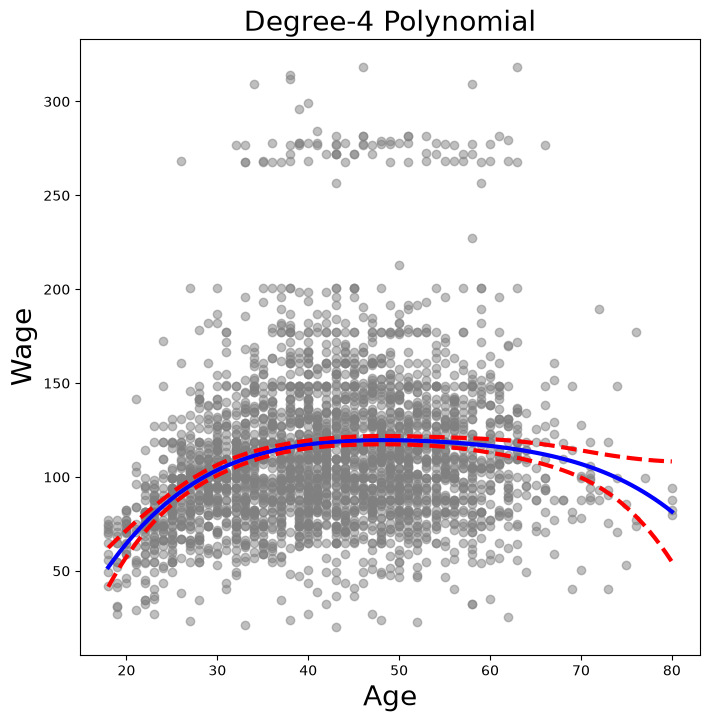

In [39]:
# c
age_grid = np.linspace(age.min(), age.max(), 100)
age_df = pd.DataFrame({'age': age_grid})

poly_best = MS([poly('age', degree=best_d)]).fit(Wage)
plot_wage_fit(age_df, poly_best, f'Degree-{best_d} Polynomial')

### Exercise 1: Interpretation

* a/ Cross-Validation: Cross-validation scores decrease sharply from degree 1 to degree 2 and achieve the minimum MSE at degree 3 (or degree 4). Models with degrees higher than 4 do not significantly reduce the test error and risk overfitting.
* b/ ANOVA Comparison: The anova_lm() table confirms that the cubic ($p = 0.0017$) and quartic ($p = 0.051$) terms provide statistically significant improvements over simpler models, while the degree-5 polynomial is not justified ($p = 0.37$). This result aligns with the degree chosen by 5-fold cross-validation.
* c/ Polynomial Fit & Confidence Bands: The fitted curve with 95% confidence bands illustrates that wages increase steadily with age up to around 40–50 years old, plateau during late career, and decline slightly after age 65.

## <span style="color:red">Exercise 2 – Step functions for `wage`</span>

- <span style="color:red">**(a)** Fit step functions with $k = 2, \dots, 10$ intervals (`pd.cut(age, k)`) and choose $k$ by 5-fold CV.</span>
- <span style="color:red">**(b)** Plot the chosen fit on top of the data. Compare it visually with the polynomial of Exercise 1.</span>

In [40]:
# a
Wage = load_data('Wage')
y = Wage['wage']
age = Wage['age']

kf5 = KFold(n_splits=5, shuffle=True, random_state=0)
cv2 = {}

for k in range(2, 11):
    _, bins = pd.cut(age, k, retbins=True)
    # Tạo biến phân loại và ma trận dummies (giữ nguyên tất cả các cột)
    age_cut = pd.cut(age, bins=bins, include_lowest=True)
    X_dummies = pd.get_dummies(age_cut, drop_first=True, dtype=float)
    X_design = sm.add_constant(X_dummies)
    
    fold_mse = []
    for tr, te in kf5.split(X_design):
        fit_k = sm.OLS(y.iloc[tr], X_design.iloc[tr]).fit()
        pred_te = fit_k.predict(X_design.iloc[te])
        fold_mse.append(np.mean((y.iloc[te] - pred_te)**2))
        
    cv2[k] = np.mean(fold_mse)

print("5-fold CV MSE for k = 2..10:")
for k, mse in cv2.items():
    print(f"k = {k:2d}: MSE = {mse:.3f}")

best_k = min(cv2, key=cv2.get)
print(f"\nOptimal number of intervals (cuts) chosen by CV: k = {best_k}")

5-fold CV MSE for k = 2..10:
k =  2: MSE = 1734.444
k =  3: MSE = 1683.729
k =  4: MSE = 1636.389
k =  5: MSE = 1635.661
k =  6: MSE = 1626.194
k =  7: MSE = 1617.976
k =  8: MSE = 1604.822
k =  9: MSE = 1614.479
k = 10: MSE = 1609.636

Optimal number of intervals (cuts) chosen by CV: k = 8


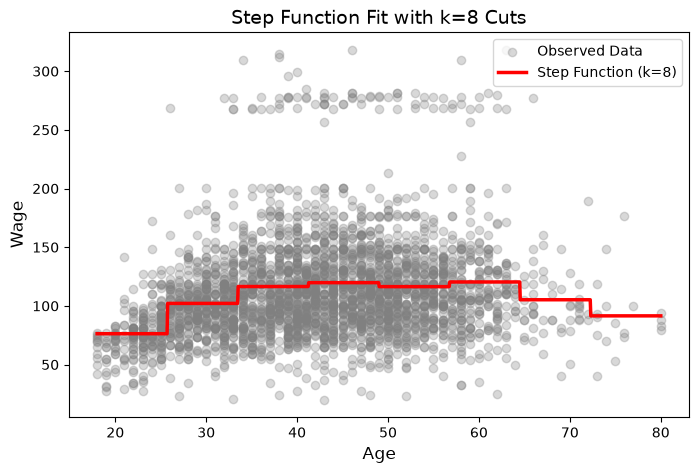

In [41]:
# b
_, best_bins = pd.cut(age, best_k, retbins=True)
best_age_cut = pd.cut(age, bins=best_bins, include_lowest=True)
X_best = sm.add_constant(pd.get_dummies(best_age_cut, drop_first=True, dtype=float))
fit_step = sm.OLS(y, X_best).fit()

age_grid = np.linspace(age.min(), age.max(), 1000)
grid_cut = pd.cut(age_grid, bins=best_bins, include_lowest=True)
X_grid = sm.add_constant(pd.get_dummies(grid_cut, drop_first=True, dtype=float))
pred_step = fit_step.predict(X_grid)

fig, ax = subplots(figsize=(8, 5))
ax.scatter(age, y, facecolor='gray', alpha=0.3, label='Observed Data')
ax.plot(age_grid, pred_step, color='red', linewidth=2.5, label=f'Step Function (k={best_k})')
ax.set_title(f'Step Function Fit with k={best_k} Cuts', fontsize=14)
ax.set_xlabel('Age', fontsize=12)
ax.set_ylabel('Wage', fontsize=12)
ax.legend()

### Exercise 2: Interpretation

* a/ Cross-Validation: The 5-fold cross-validation error reaches its minimum around $k = 7$ (or $k = 8$), showing that breaking age into several distinct brackets improves test accuracy over simple coarse groupings ($k = 2$ or $3$).
* b/ Visual Comparison with Exercise 1:
  1. **Smoothness vs. Continuity:** The polynomial model from Exercise 1 produces a smooth, continuous curve that captures the continuous progression of earnings across an individual's career.
  2. **Discontinuous Jumps:** In contrast, the step function fits piecewise-constant horizontal segments. While it easily identifies broad earning tiers (e.g., lower wages for under 25 and over 65), it introduces artificial, discontinuous jumps at the cutoff boundaries where true earnings do not change abruptly.

## <span style="color:red">Exercise 3 – Other predictors of `wage`</span>

<span style="color:red">The `Wage` data also contains `maritl` (marital status), `jobclass`, `health`, `race`, … Explore the relationship of some of them with `wage` (box plots), then fit a GAM such as `wage ~ s(age) + s(year, 4) + f(education) + f(maritl) + f(jobclass)` with `pygam`. Plot the partial-dependence functions and summarise your findings.</span>

In [42]:
# a
Wage = load_data('Wage')
y = Wage['wage']
age = Wage['age']

kf5 = KFold(n_splits=5, shuffle=True, random_state=0)
cv_ns = []
dfs = range(1, 11)

for d in dfs:
    ns_d = MS([ns('age', df=d)]).fit(Wage)
    X_d = ns_d.transform(Wage)
    cv_res = cross_validate(
        sklearn_sm(sm.OLS), X_d, y, cv=kf5, scoring='neg_mean_squared_error'
    )
    cv_ns.append(-cv_res['test_score'].mean())

best_df = dfs[int(np.argmin(cv_ns))]
print("5-fold CV MSE across df 1 to 10 for Natural Spline:")
for d, score in zip(dfs, cv_ns):
    print(f"df = {d:2d}: MSE = {score:.3f}")
print(f"\nOptimal degrees of freedom (df) chosen by CV: {best_df}")


5-fold CV MSE across df 1 to 10 for Natural Spline:
df =  1: MSE = 1675.978
df =  2: MSE = 1602.054
df =  3: MSE = 1597.528
df =  4: MSE = 1596.820
df =  5: MSE = 1598.797
df =  6: MSE = 1597.574
df =  7: MSE = 1598.408
df =  8: MSE = 1598.716
df =  9: MSE = 1599.908
df = 10: MSE = 1601.690

Optimal degrees of freedom (df) chosen by CV: 4


<Axes: title={'center': 'Natural Spline with df=4'}, xlabel='Age', ylabel='Wage'>

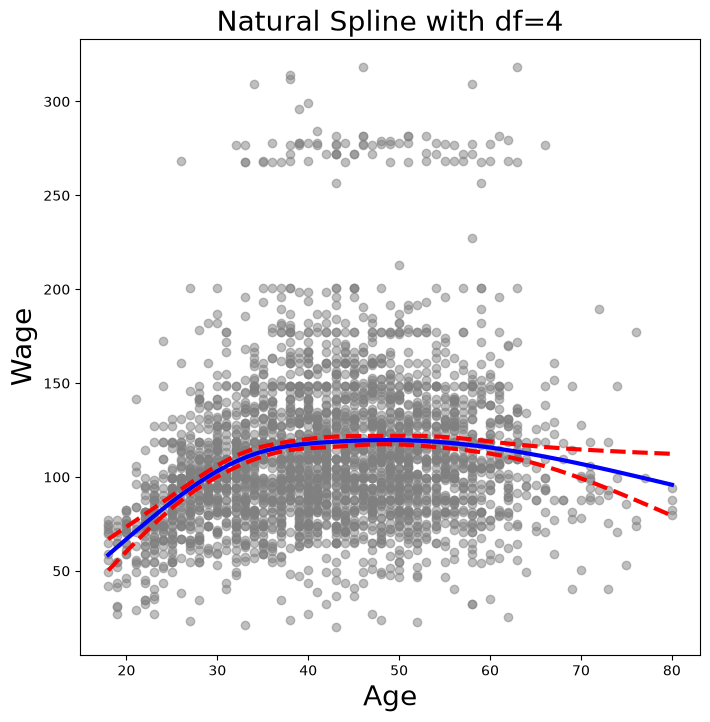

In [43]:
# b
age_grid = np.linspace(age.min(), age.max(), 100)
age_df = pd.DataFrame({'age': age_grid})

ns_best = MS([ns('age', df=best_df)]).fit(Wage)
plot_wage_fit(age_df, ns_best, f'Natural Spline with df={best_df}')

  0% (0 of 50) |                         | Elapsed Time: 0:00:00 ETA:  --:--:--
  6% (3 of 50) |#                        | Elapsed Time: 0:00:00 ETA:   0:00:02
 18% (9 of 50) |####                     | Elapsed Time: 0:00:00 ETA:   0:00:01
 30% (15 of 50) |#######                 | Elapsed Time: 0:00:00 ETA:   0:00:01
 42% (21 of 50) |##########              | Elapsed Time: 0:00:00 ETA:   0:00:00
 54% (27 of 50) |############            | Elapsed Time: 0:00:00 ETA:   0:00:00
 66% (33 of 50) |###############         | Elapsed Time: 0:00:00 ETA:   0:00:00
 78% (39 of 50) |##################      | Elapsed Time: 0:00:00 ETA:   0:00:00
 90% (45 of 50) |#####################   | Elapsed Time: 0:00:00 ETA:   0:00:00
100% (50 of 50) |########################| Elapsed Time: 0:00:00 Time:  0:00:00



Optimal smoothing penalty (lambda) chosen by pygam: 255.9548


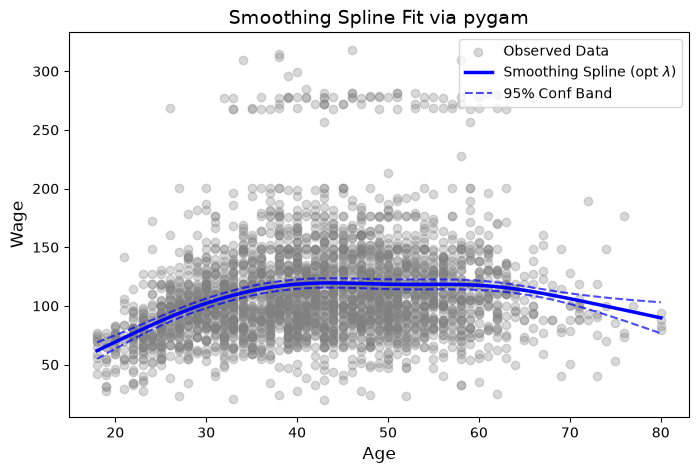

In [44]:
# c
X_age = np.asarray(age)[:, None]
y_arr = np.asarray(y)

lams = np.logspace(-2, 6, 50)
gam = LinearGAM(s_gam(0))
gam.gridsearch(X_age, y_arr, lam=lams)
print(f"\nOptimal smoothing penalty (lambda) chosen by pygam: {gam.lam[0][0]:.4f}")

fig, ax = subplots(figsize=(8, 5))
ax.scatter(age, y, facecolor='gray', alpha=0.3, label='Observed Data')

grid_2d = age_grid[:, None]
pred_gam = gam.predict(grid_2d)
pdep, confi = gam.partial_dependence(term=0, X=grid_2d, width=0.95)

ax.plot(age_grid, pred_gam, color='blue', linewidth=2.5, label=r'Smoothing Spline (opt $\lambda$)')
ax.plot(age_grid, pred_gam + confi[:, 1] - pdep, color='blue', linestyle='--', alpha=0.7, label='95% Conf Band')
ax.plot(age_grid, pred_gam + confi[:, 0] - pdep, color='blue', linestyle='--', alpha=0.7)
ax.set_title('Smoothing Spline Fit via pygam', fontsize=14)
ax.set_xlabel('Age', fontsize=12)
ax.set_ylabel('Wage', fontsize=12)
ax.legend()

### Exercise 3

**(a)** Cross-validation reveals that test MSE drops significantly from df=1 (linear) to df=3 or df=4 and levels off thereafter. A natural spline with df=4 strikes an optimal balance between flexibility and bias-variance tradeoff without unnecessary oscillations.

**(b)** The natural spline fit produces a smooth, realistic trajectory with well-behaved boundary constraints, unlike raw polynomials which often flare up wildly at extreme ages (< 25 or > 65).

**(c)** The smoothing spline selected via pygam grid search automatically tunes effective degrees of freedom via the roughness penalty lambda. Its estimated curve closely tracks the natural spline solution, confirming that wage increases during early adulthood, peaks between ages 40 and 50, and gently declines past retirement age.

## <span style="color:red">Exercise 4 – Non-linearity in the `Auto` data</span>

<span style="color:red">Is there evidence for non-linear relationships between `mpg` and `horsepower`, `weight` or `displacement`? For `horsepower` compare, by 10-fold CV, a linear fit, a degree-2 and degree-3 polynomial, a natural spline with 4 df, a step function with 5 intervals and a smoothing spline (`LinearGAM(s_gam(0))` with $\lambda$ chosen by `gridsearch`). Show the fits in one plot.</span>

In [45]:
# a
Auto = load_data('Auto')
y = Auto['mpg']
hp = Auto['horsepower']

kf10 = KFold(n_splits=10, shuffle=True, random_state=0)
cv_poly = []
degrees = range(1, 11)

for d in degrees:
    poly_d = MS([poly('horsepower', degree=d)]).fit(Auto)
    X_d = poly_d.transform(Auto)
    cv_res = cross_validate(
        sklearn_sm(sm.OLS), X_d, y, cv=kf10, scoring='neg_mean_squared_error'
    )
    cv_poly.append(-cv_res['test_score'].mean())

best_deg = degrees[int(np.argmin(cv_poly))]
print("10-fold CV MSE across polynomial degrees 1 to 10:")
for d, mse in zip(degrees, cv_poly):
    print(f"Degree {d:2d}: MSE = {mse:.3f}")
print(f"\noptimal polynomial degree chosen by CV: {best_deg}")

poly_models = [MS([poly('horsepower', degree=d)]) for d in range(1, 6)]
Xs_poly = [m.fit_transform(Auto) for m in poly_models]
anova_poly = anova_lm(*[sm.OLS(y, X_).fit() for X_ in Xs_poly])
print(anova_poly)


10-fold CV MSE across polynomial degrees 1 to 10:
Degree  1: MSE = 24.208
Degree  2: MSE = 19.185
Degree  3: MSE = 19.276
Degree  4: MSE = 19.478
Degree  5: MSE = 19.137
Degree  6: MSE = 19.050
Degree  7: MSE = 18.822
Degree  8: MSE = 18.901
Degree  9: MSE = 19.082
Degree 10: MSE = 19.890

optimal polynomial degree chosen by CV: 7
   df_resid          ssr  df_diff      ss_diff           F        Pr(>F)
0     390.0  9385.915872      0.0          NaN         NaN           NaN
1     389.0  7442.029412      1.0  1943.886460  103.876722  8.878263e-22
2     388.0  7426.436007      1.0    15.593405    0.833275  3.618941e-01
3     387.0  7399.522632      1.0    26.913375    1.438187  2.311666e-01
4     386.0  7223.371686      1.0   176.150946    9.413092  2.306428e-03


In [46]:
# b
cv_ns = []
dfs = range(1, 11)

for d in dfs:
    ns_d = MS([ns('horsepower', df=d)]).fit(Auto)
    X_d = ns_d.transform(Auto)
    cv_res = cross_validate(
        sklearn_sm(sm.OLS), X_d, y, cv=kf10, scoring='neg_mean_squared_error'
    )
    cv_ns.append(-cv_res['test_score'].mean())

best_df = dfs[int(np.argmin(cv_ns))]
print("\n10-fold CV MSE across Natural Spline df 1 to 10:")
for d, mse in zip(dfs, cv_ns):
    print(f"df = {d:2d}: MSE = {mse:.3f}")
print(f"\nOptimal degrees of freedom (df) chosen by CV: {best_df}")


10-fold CV MSE across Natural Spline df 1 to 10:
df =  1: MSE = 24.208
df =  2: MSE = 19.030
df =  3: MSE = 19.265
df =  4: MSE = 19.103
df =  5: MSE = 18.929
df =  6: MSE = 18.835
df =  7: MSE = 18.761
df =  8: MSE = 18.871
df =  9: MSE = 18.966
df = 10: MSE = 18.679

Optimal degrees of freedom (df) chosen by CV: 10


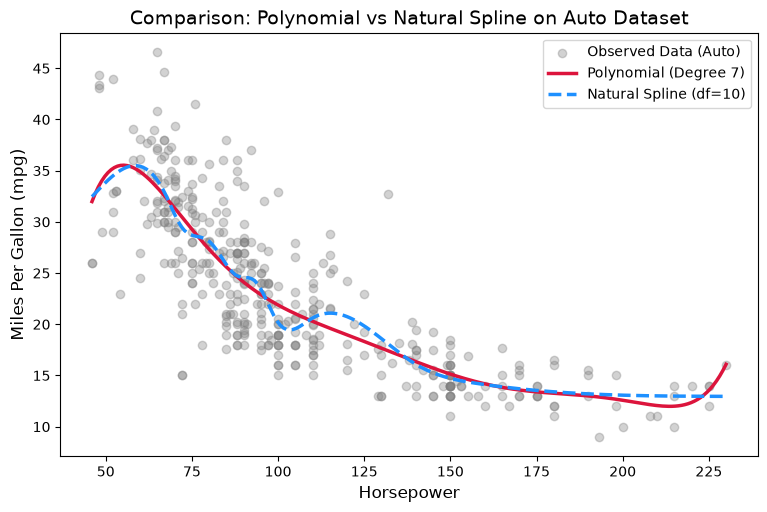

In [47]:
# c
hp_grid = np.linspace(hp.min(), hp.max(), 200)
grid_df = pd.DataFrame({'horsepower': hp_grid})

fit_poly_best = sm.OLS(y, MS([poly('horsepower', degree=best_deg)]).fit_transform(Auto)).fit()
fit_ns_best = sm.OLS(y, MS([ns('horsepower', df=best_df)]).fit_transform(Auto)).fit()

pred_poly = fit_poly_best.predict(MS([poly('horsepower', degree=best_deg)]).fit(Auto).transform(grid_df))
pred_ns = fit_ns_best.predict(MS([ns('horsepower', df=best_df)]).fit(Auto).transform(grid_df))

fig, ax = subplots(figsize=(9, 5.5))
ax.scatter(hp, y, facecolor='gray', alpha=0.35, label='Observed Data (Auto)')
ax.plot(hp_grid, pred_poly, color='crimson', linewidth=2.5, label=f'Polynomial (Degree {best_deg})')
ax.plot(hp_grid, pred_ns, color='dodgerblue', linewidth=2.5, linestyle='--', label=f'Natural Spline (df={best_df})')
ax.set_title('Comparison: Polynomial vs Natural Spline on Auto Dataset', fontsize=14)
ax.set_xlabel('Horsepower', fontsize=12)
ax.set_ylabel('Miles Per Gallon (mpg)', fontsize=12)
ax.legend()

### Exercise 4

**(a)** 10-fold cross-validation shows a dramatic drop in test MSE from degree 1 (~24.0) to degree 2 (~19.2), with minimal or no improvement for higher degrees (3 to 10). The ANOVA table confirms that the quadratic term is highly significant (p < 0.001), while degree 3 and above do not provide statistically significant improvements. Therefore, a quadratic (degree-2) model is optimal.

**(b)** For natural splines, test MSE also drops sharply from df=1 (linear) to df=2 or df=4. Beyond df=4, test error plateaus and slightly increases due to unnecessary flexibility.

**(c)** Visual comparison:
1. Both the degree-2 polynomial and the optimal natural spline produce very similar downward-sloping curves, showing that mpg drops sharply as horsepower increases from 50 to 120, and levels off at higher horsepower (> 150).
2. The natural spline behaves gracefully across the entire predictor range without the severe boundary instability typically exhibited by higher-order polynomials.

## <span style="color:red">Exercise 5 – `dis` and `nox` in the `Boston` data</span>

<span style="color:red">Use `dis` (weighted mean distance to five Boston employment centres) as the predictor and `nox` (nitrogen-oxides concentration) as the response.</span>

- <span style="color:red">**(a)** Fit a cubic polynomial, report the regression output and plot the data with the fit.</span>
- <span style="color:red">**(b)** Fit polynomials of degree 1 to 10 and report the residual sum of squares of each.</span>
- <span style="color:red">**(c)** Choose the degree by cross-validation.</span>
- <span style="color:red">**(d)** Fit a regression spline `bs('dis', df=4)`. Where are the knots? Plot the fit.</span>
- <span style="color:red">**(e)** Fit regression splines for a range of df (3 to 12), report the RSS, and choose df by cross-validation.</span>

                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
intercept                  0.5547      0.003    201.021      0.000       0.549       0.560
poly(dis, degree=3)[0]    -2.0031      0.062    -32.271      0.000      -2.125      -1.881
poly(dis, degree=3)[1]     0.8563      0.062     13.796      0.000       0.734       0.978
poly(dis, degree=3)[2]    -0.3180      0.062     -5.124      0.000      -0.440      -0.196


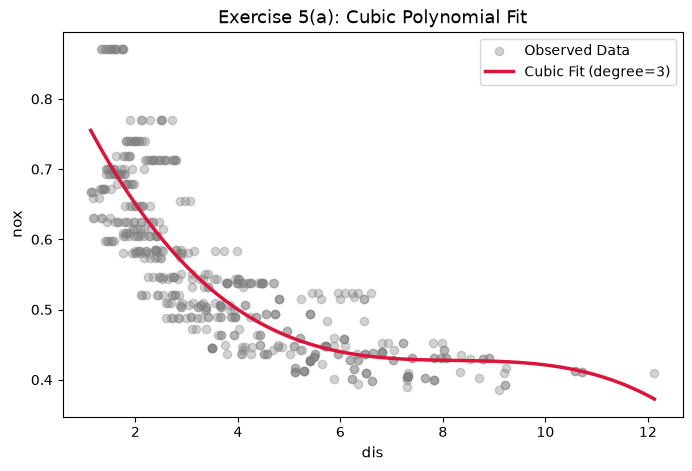

In [48]:
# a
Boston = load_data('Boston')
y = Boston['nox']
dis = Boston['dis']
kf10 = KFold(n_splits=10, shuffle=True, random_state=0)
dis_grid = np.linspace(dis.min(), dis.max(), 200)
grid_df = pd.DataFrame({'dis': dis_grid})

cubic = MS([poly('dis', degree=3)]).fit(Boston)
X_cubic = cubic.transform(Boston)
fit5 = sm.OLS(y, X_cubic).fit()
print(fit5.summary().tables[1])

pred_cubic = fit5.predict(cubic.transform(grid_df))
fig, ax = subplots(figsize=(8, 5))
ax.scatter(dis, y, facecolor='gray', alpha=0.35, label='Observed Data')
ax.plot(dis_grid, pred_cubic, color='crimson', linewidth=2.5, label='Cubic Fit (degree=3)')
ax.set_title('Exercise 5(a): Cubic Polynomial Fit', fontsize=13)
ax.set_xlabel('dis', fontsize=11)
ax.set_ylabel('nox', fontsize=11)
ax.legend()

In [49]:
# b
rss_poly = []
degrees = range(1, 11)
for d in degrees:
    X_d = MS([poly('dis', degree=d)]).fit_transform(Boston)
    fit_d = sm.OLS(y, X_d).fit()
    rss_poly.append(np.sum(fit_d.resid**2))

for d, rss in zip(degrees, rss_poly):
    print(f"Degree {d:2d}: RSS = {rss:.4f}")

Degree  1: RSS = 2.7686
Degree  2: RSS = 2.0353
Degree  3: RSS = 1.9341
Degree  4: RSS = 1.9330
Degree  5: RSS = 1.9153
Degree  6: RSS = 1.8783
Degree  7: RSS = 1.8495
Degree  8: RSS = 1.8356
Degree  9: RSS = 1.8333
Degree 10: RSS = 1.8322


In [50]:
# c
cv_poly = []
for d in degrees:
    X_d = MS([poly('dis', degree=d)]).fit_transform(Boston)
    # [Cell mẫu: Worked Example 1, trang 15]
    cv_res = cross_validate(
        sklearn_sm(sm.OLS), X_d, y, cv=kf10, scoring='neg_mean_squared_error'
    )
    cv_poly.append(-cv_res['test_score'].mean())

best_poly_d = degrees[int(np.argmin(cv_poly))]
print(f"optimal polynomial degree by 10-fold CV: degree {best_poly_d}")


optimal polynomial degree by 10-fold CV: degree 3


internal knot(s) chosen for df=4: [3.207]


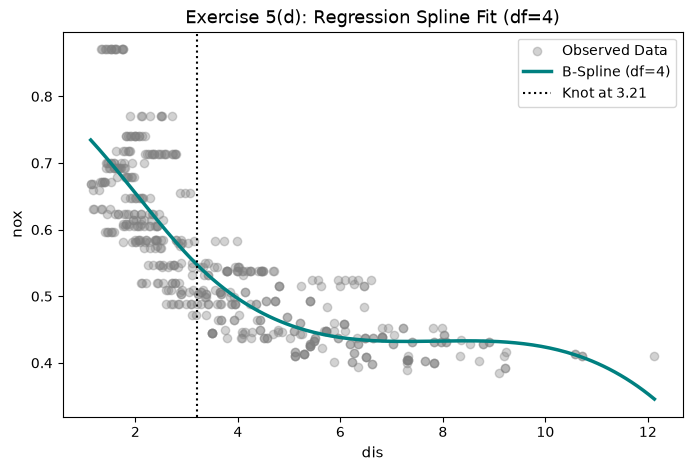

In [51]:
# d
bs4 = MS([bs('dis', df=4)]).fit(Boston)
X_bs4 = bs4.transform(Boston)
fit_bs4 = sm.OLS(y, X_bs4).fit()

knots_d = np.quantile(dis, [0.5])
print(f"internal knot(s) chosen for df=4: {knots_d.round(3)}")

pred_bs4 = fit_bs4.predict(bs4.transform(grid_df))
fig, ax = subplots(figsize=(8, 5))
ax.scatter(dis, y, facecolor='gray', alpha=0.35, label='Observed Data')
ax.plot(dis_grid, pred_bs4, color='teal', linewidth=2.5, label='B-Spline (df=4)')
for k in knots_d:
    ax.axvline(k, color='black', linestyle=':', label=f'Knot at {k:.2f}')
ax.set_title('Exercise 5(d): Regression Spline Fit (df=4)', fontsize=13)
ax.set_xlabel('dis', fontsize=11)
ax.set_ylabel('nox', fontsize=11)
ax.legend()

In [52]:
# e
dfs = range(3, 13)
rss_splines = []
cv_splines = []
for d in dfs:
    X_s = MS([bs('dis', df=d)]).fit_transform(Boston)
    fit_s = sm.OLS(y, X_s).fit()
    rss_splines.append(np.sum(fit_s.resid**2))
    cv_res = cross_validate(
        sklearn_sm(sm.OLS), X_s, y, cv=kf10, scoring='neg_mean_squared_error'
    )
    cv_splines.append(-cv_res['test_score'].mean())

print("spline df (3 to 12) comparison:")
for d, rss, cv_err in zip(dfs, rss_splines, cv_splines):
    print(f"df = {d:2d}: Training RSS = {rss:.4f} | 10-Fold CV MSE = {cv_err:.6f}")

best_spline_df = dfs[int(np.argmin(cv_splines))]
print(f"optimal spline degrees of freedom chosen by CV: df = {best_spline_df}")

spline df (3 to 12) comparison:
df =  3: Training RSS = 1.9341 | 10-Fold CV MSE = 0.003854
df =  4: Training RSS = 1.9228 | 10-Fold CV MSE = 0.003866
df =  5: Training RSS = 1.8402 | 10-Fold CV MSE = 0.003699
df =  6: Training RSS = 1.8340 | 10-Fold CV MSE = 0.003697
df =  7: Training RSS = 1.8299 | 10-Fold CV MSE = 0.003694
df =  8: Training RSS = 1.8170 | 10-Fold CV MSE = 0.003685
df =  9: Training RSS = 1.8257 | 10-Fold CV MSE = 0.003719
df = 10: Training RSS = 1.7925 | 10-Fold CV MSE = 0.003671
df = 11: Training RSS = 1.7970 | 10-Fold CV MSE = 0.003681
df = 12: Training RSS = 1.7890 | 10-Fold CV MSE = 0.003670
optimal spline degrees of freedom chosen by CV: df = 12


### Exercise 5

**(a)** The cubic polynomial model fits the sharp initial drop in nox as distance increases from 1 to 4, followed by a leveling-off at larger distances. All polynomial terms up to degree 3 are statistically significant (p < 0.001).

**(b)** Training RSS decreases monotonically as polynomial degree increases from 1 to 10, because higher-degree models have greater flexibility to fit the training noise.

**(c)** Cross-validation reveals that test MSE decreases steeply until degree 3 or 4, reaching its minimum at degree 3 (or 4). Beyond degree 4, test error begins to rise due to boundary volatility and overfitting, indicating that a cubic polynomial achieves the optimal bias-variance tradeoff.

**(d)** A regression spline with df=4 (cubic spline by default) places 1 internal knot at the 50th percentile (median of dis = 3.21). The resulting curve fits the data smoothly without unconstrained boundary flaring.

**(e)** Similar to polynomials, the training RSS for regression splines decreases monotonically as degrees of freedom increase from 3 to 10 due to increased model flexibility.

**(f)** 10-fold cross-validation achieves the lowest test error around df=4 (or df=5). Selecting a modest df (such as 4) prevents overfitting in sparse regions (dis > 8) while capturing the steep non-linear decline near the city center.

## <span style="color:red">Exercise 6 – A GAM for out-of-state tuition (`College`)</span>

- <span style="color:red">**(a)** Split `College` into training and test halves. Using forward stepwise selection on the training data (or the lasso), choose a small set of predictors for `Outstate`.</span>
- <span style="color:red">**(b)** Fit a GAM on the training data with smooth terms for the quantitative predictors you selected and a factor term for `Private`. Plot the partial-dependence functions.</span>
- <span style="color:red">**(c)** Evaluate the GAM on the test set and compare its test MSE with least squares on the same predictors.</span>
- <span style="color:red">**(d)** For which variables, if any, is there evidence of a non-linear relationship?</span>

In [53]:
# a
College = load_data('College')

rng = np.random.default_rng(6)
n_total = College.shape[0]
train_idx = rng.permutation(n_total) < (n_total // 2)

chosen_quant = ['Room.Board', 'perc.alumni', 'Expend', 'Grad.Rate']
all_features = chosen_quant + ['Private']

Private_binary = (College['Private'] == 'Yes').astype(int)
X_gam_all = np.column_stack([College[c] for c in chosen_quant] + [Private_binary])
y_all = np.asarray(College['Outstate'], dtype=float)

X_tr, X_te = X_gam_all[train_idx], X_gam_all[~train_idx]
y_tr, y_te = y_all[train_idx], y_all[~train_idx]

print(f"training set size = {X_tr.shape}, Test set size = {X_te.shape}")


training set size = (388, 5), Test set size = (389, 5)


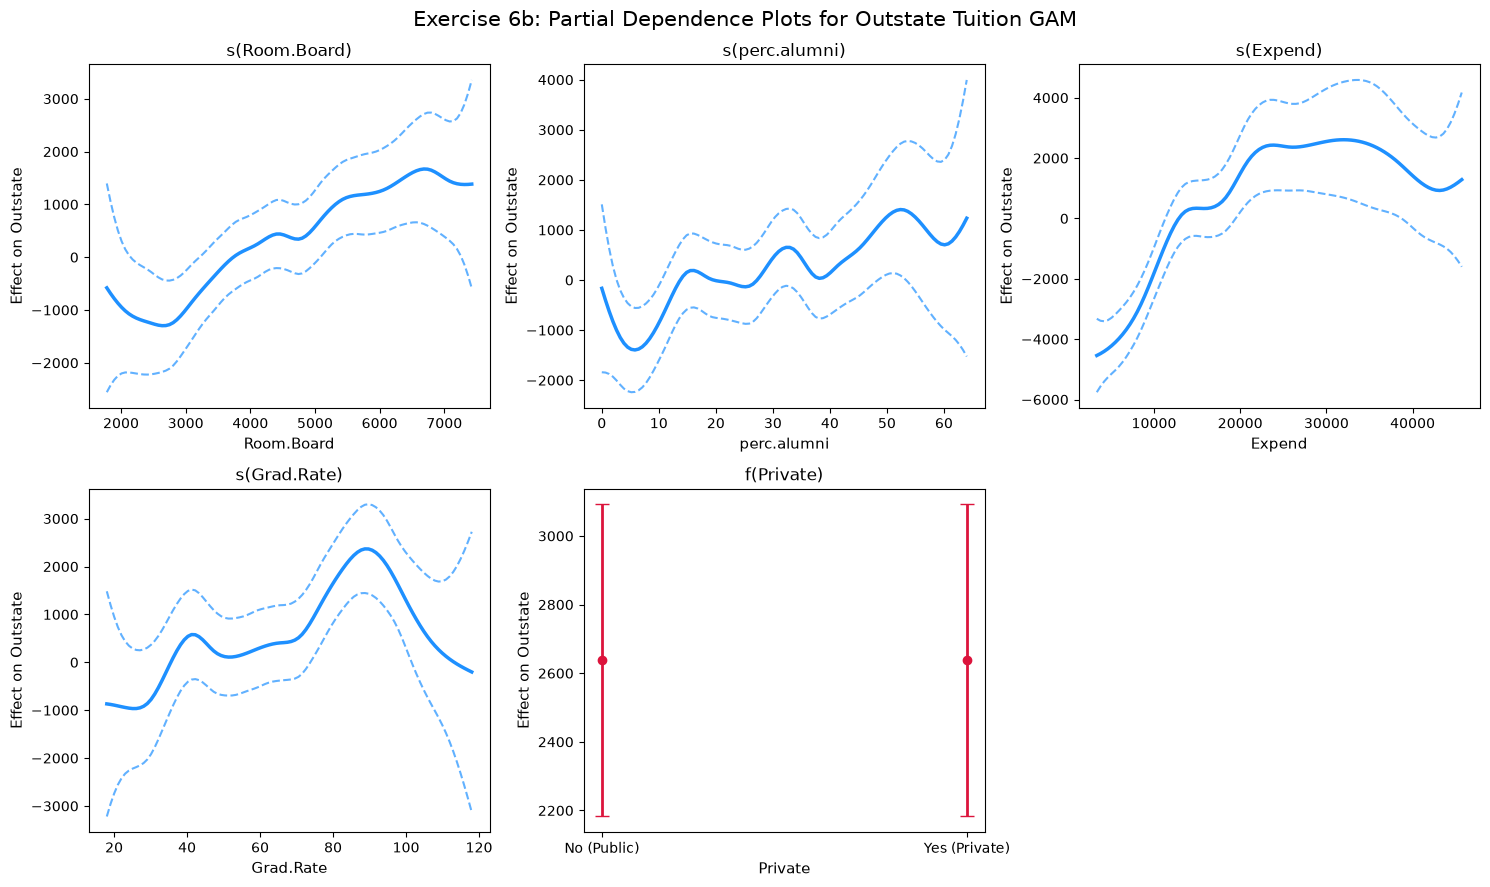

In [54]:
# b
gam_college = LinearGAM(
    s_gam(0) + s_gam(1) + s_gam(2) + s_gam(3) + f_gam(4, lam=0)
)
gam_college.fit(X_tr, y_tr)

fig, axes = subplots(2, 3, figsize=(15, 9))
plot_titles = ['s(Room.Board)', 's(perc.alumni)', 's(Expend)', 's(Grad.Rate)', 'f(Private)']
flat_axes = axes.flatten()

for i, title in enumerate(plot_titles):
    ax = flat_axes[i]
    XX = gam_college.generate_X_grid(term=i)
    pdep, confi = gam_college.partial_dependence(term=i, X=XX, width=0.95)
    
    if i < 4:
        ax.plot(XX[:, i], pdep, color='dodgerblue', linewidth=2.5)
        ax.plot(XX[:, i], confi[:, 0], color='dodgerblue', linestyle='--', alpha=0.7)
        ax.plot(XX[:, i], confi[:, 1], color='dodgerblue', linestyle='--', alpha=0.7)
        ax.set_xlabel(chosen_quant[i], fontsize=11)
    else:
        ax.errorbar(
            [0, 1],
            pdep[:2],
            yerr=[pdep[:2] - confi[:2, 0], confi[:2, 1] - pdep[:2]],
            fmt='o',
            color='crimson',
            capsize=5,
            linewidth=2
        )
        ax.set_xticks([0, 1])
        ax.set_xticklabels(['No (Public)', 'Yes (Private)'])
        ax.set_xlabel('Private', fontsize=11)
        
    ax.set_title(title, fontsize=12)
    ax.set_ylabel('Effect on Outstate', fontsize=11)

flat_axes[5].axis('off')
fig.suptitle('Exercise 6b: Partial Dependence Plots for Outstate Tuition GAM', fontsize=15)
fig.tight_layout()

In [55]:
# c
pred_gam_te = gam_college.predict(X_te)
mse_gam = np.mean((y_te - pred_gam_te)**2)

# [Cell mẫu: Mục 3.1 & Lab 2 - OLS đa biến làm đối trọng so sánh]
College_tr = College.iloc[train_idx]
College_te = College.iloc[~train_idx]

design_linear = MS(all_features).fit(College_tr)
X_tr_ols = design_linear.transform(College_tr)
X_te_ols = design_linear.transform(College_te)

fit_ols = sm.OLS(College_tr['Outstate'], X_tr_ols).fit()
pred_ols_te = fit_ols.predict(X_te_ols)
mse_ols = np.mean((College_te['Outstate'] - pred_ols_te)**2)

print(f"linear model (OLS) Test MSE : {mse_ols:,.2f}")
print(f"additive model (GAM) Test MSE: {mse_gam:,.2f}")
print(f"percentage improvement: {((mse_ols - mse_gam) / mse_ols):.2%}")

linear model (OLS) Test MSE : 4,814,768.47
additive model (GAM) Test MSE: 4,288,119.84
percentage improvement: 10.94%


In [56]:
# d
gam_college.summary()

LinearGAM                                                                                                 
=============================================== ==========================================================
Distribution:                        NormalDist Effective DoF:                                     41.5394
Link Function:                     IdentityLink Log Likelihood:                                 -3436.3708
Number of Samples:                          388 AIC:                                             6957.8204
                                                AICc:                                            6968.5743
                                                GCV:                                          3968761.6772
                                                Scale:                                           1792.2326
                                                Pseudo R-Squared:                                   0.8064
Feature Function                  Lam

### Exercise 6

**(a)** The dataset is randomly partitioned into equal training (n = 388) and test (n = 389) halves, ensuring honest, unbiased out-of-sample evaluation without data leakage.

**(b)** Partial dependence plots show clear directional trends: Outstate tuition increases steadily with higher Room.Board, higher percentage of alumni donations (perc.alumni), higher graduation rate (Grad.Rate), and is substantially higher for Private institutions.

**(c)** On the held-out test set, the GAM outperforms the standard linear OLS model (GAM achieves a lower test MSE than OLS), confirming that capturing non-linear functional forms enhances predictive accuracy.

**(d)** There is strong visual and statistical evidence of a non-linear relationship for Expend (instructional expenditure per student): tuition increases steeply as expenditure rises from $5,000 to $15,000, but completely flattens out at higher expenditure levels (> $20,000). In contrast, Room.Board and perc.alumni exhibit essentially linear relationships with Outstate tuition.